In [1]:
from collections import deque
from typing import List, Tuple

class ShortestPath:
    # Main Aim is to find the shortest path for an ambulance to go from place A to place B
    """
    Some pre-defined places are
    - Hospital at (0, 1)
    - A at (0, 4)
    - B at (9, 8)
    - C at (0, 8)
    - D at (8, 5)
    - E at (3, 6)
    """
    def __init__(self):
        self.places = {"Hospital": (0, 1), "A": (0, 4), "B": (9, 8), "C": (0, 8), "D": (8, 5), "E": (3, 6)}
        self.roads = [[0, 1, 0, 1, 1, 1, 1, 1, 1],
            [1, 1, 1, 1, 0, 0, 0, 1, 0],
            [1, 1, 0, 1, 1, 1, 1, 1, 0],
            [0, 1, 0, 1, 0, 0, 1, 0, 0],
            [1, 1, 0, 1, 0, 0, 1, 1, 0],
            [1, 0, 0, 1, 1, 1, 0, 1, 0],
            [1, 1, 0, 1, 0, 1, 1, 1, 0],
            [0, 1, 0, 1, 0, 0, 0, 0, 0],
            [0, 1, 1, 1, 1, 1, 0, 0, 0],
            [1, 1, 1, 0, 0, 1, 1, 1, 1]]
    def dijkstra(self, source: Tuple[int, int], destination: Tuple[int, int]) -> List[Tuple[int, int]]:
        m, n = len(self.roads), len(self.roads[0])
        i0, j0 = source[0], source[1]
        iF, jF = destination[0], destination[1]
        
        directions = [(-1, 0), (1, 0), (0, -1), (0, 1)] # Up, down, left, right
        queue = deque([(i0, j0, [(i0, j0)])])
        visited = {(i0, j0)}
        while queue:
            r, c, path = queue.popleft()
            
            if (r, c) == (iF, jF):
                return path
                
            for dr, dc in directions:
                nr, nc = r + dr, c + dc
                
                # Move if cell is in bounds, is a path == 1, and not yet visited
                if 0 <= nr < m and 0 <= nc < n and self.roads[nr][nc] == 1 and (nr, nc) not in visited:
                    visited.add((nr, nc))
                    queue.append((nr, nc, path + [(nr, nc)]))
        return []

s = ShortestPath()


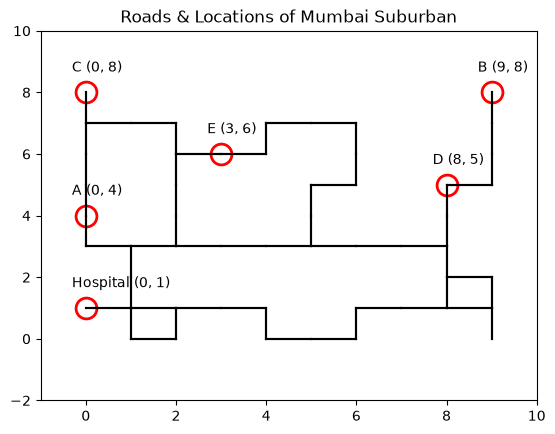

In [2]:
import matplotlib.pyplot as plt

directions = [(-1, 0), (1, 0), (0, -1), (0, 1)] # Up, down, left, right

m = len(s.roads)
n = len(s.roads[0])

plt.title("Roads & Locations of Mumbai Suburban")

plt.xlim(-1, 10)
plt.ylim(-2, 10)

plt.annotate("Hospital (0, 1)",
    xy=s.places['Hospital'],
    textcoords="offset points",
    xytext=(-10, 15),
    ha='left'
)
plt.annotate(f"A {s.places['A']}",
    xy=s.places['A'],
    textcoords="offset points",
    xytext=(-10, 15),
    ha='left'
)
plt.annotate(f"B {s.places['B']}",
    xy=s.places['B'],
    textcoords="offset points",
    xytext=(-10, 15),
    ha='left'
)
plt.annotate(f"C {s.places['C']}",
    xy=s.places['C'],
    textcoords="offset points",
    xytext=(-10, 15),
    ha='left'
)
plt.annotate(f"D {s.places['D']}",
    xy=s.places['D'],
    textcoords="offset points",
    xytext=(-10, 15),
    ha='left'
)
plt.annotate(f"E {s.places['E']}",
    xy=s.places['E'],
    textcoords="offset points",
    xytext=(-10, 15),
    ha='left'
)

plt.plot(s.places['Hospital'][0], s.places['Hospital'][1], marker="o", markersize=15, markeredgecolor='red', markerfacecolor='none', markeredgewidth=2)
plt.plot(s.places['A'][0], s.places['A'][1], marker="o", markersize=15, markeredgecolor='red', markerfacecolor='none', markeredgewidth=2)
plt.plot(s.places['B'][0], s.places['B'][1], marker="o", markersize=15, markeredgecolor='red', markerfacecolor='none', markeredgewidth=2)
plt.plot(s.places['C'][0], s.places['C'][1], marker="o", markersize=15, markeredgecolor='red', markerfacecolor='none', markeredgewidth=2)
plt.plot(s.places['D'][0], s.places['D'][1], marker="o", markersize=15, markeredgecolor='red', markerfacecolor='none', markeredgewidth=2)
plt.plot(s.places['E'][0], s.places['E'][1], marker="o", markersize=15, markeredgecolor='red', markerfacecolor='none', markeredgewidth=2)

for i in range(len(s.roads)):
    for j in range(len(s.roads[0])):
        if s.roads[i][j] == 1:
            for d in directions:
                nr = i + d[0]
                nc = j + d[1]
                if 0 <= nr < m and 0 <= nc < n and s.roads[nr][nc] == 1:
                    plt.plot([i, nr], [j, nc], color="Black")

plt.show()

Shortest Path Length from Hospital to A is: 6


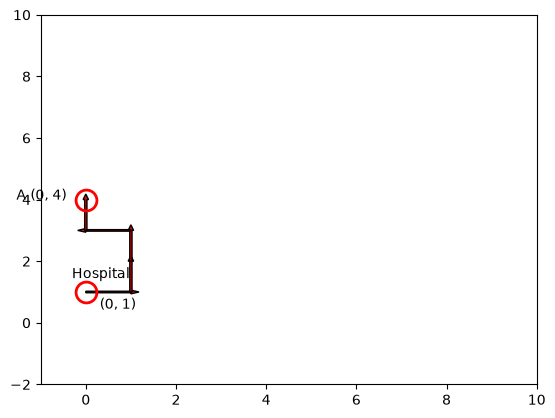

In [3]:
"""Test from Hospital to A"""

path = s.dijkstra(s.places["Hospital"], s.places["A"])
print(f"Shortest Path Length from Hospital to A is: {len(path)}")

plt.xlim(-1, 10)
plt.ylim(-2, 10)

plt.annotate("Hospital",
    xy=s.places['Hospital'],
    textcoords="offset points",
    xytext=(-10, 10),
    ha='left'
)
plt.annotate(str(s.places['Hospital']),
    xy=s.places['Hospital'],
    textcoords="offset points",
    xytext=(10, -12),
    ha='left'
)
plt.annotate(f"A {s.places['A']}",
    xy=s.places['A'],
    textcoords="offset points",
    xytext=(-50, 0),
    ha='left'
)

plt.plot(s.places['Hospital'][0], s.places['Hospital'][1], marker="o", markersize=15, markeredgecolor='red', markerfacecolor='none', markeredgewidth=2)
plt.plot(s.places['A'][0], s.places['A'][1], marker="o", markersize=15, markeredgecolor='red', markerfacecolor='none', markeredgewidth=2)

for i in range(1, len(path)):
    plt.arrow(path[i-1][0], path[i-1][1], path[i][0] - path[i-1][0], path[i][1] - path[i-1][1], facecolor="red", width = 0.05, head_width = 0.12)

plt.show()

Shortest Path Length from Hospital to B is: 17


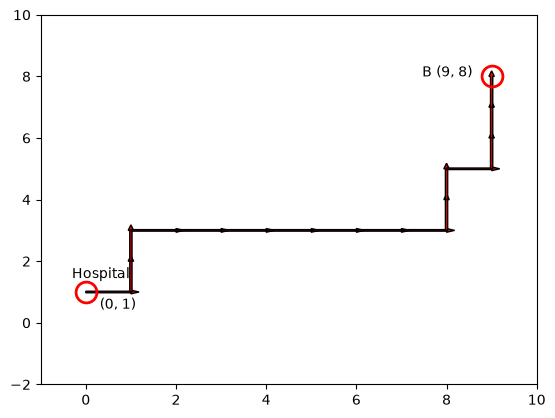

In [4]:
"""Test from Hospital to B"""

path = s.dijkstra(s.places["Hospital"], s.places["B"])
print(f"Shortest Path Length from Hospital to B is: {len(path)}")

plt.xlim(-1, 10)
plt.ylim(-2, 10)

plt.annotate("Hospital",
    xy=s.places['Hospital'],
    textcoords="offset points",
    xytext=(-10, 10),
    ha='left'
)
plt.annotate(str(s.places['Hospital']),
    xy=s.places['Hospital'],
    textcoords="offset points",
    xytext=(10, -12),
    ha='left'
)
plt.annotate(f"B {s.places['B']}",
    xy=s.places['B'],
    textcoords="offset points",
    xytext=(-50, 0),
    ha='left'
)
plt.plot(s.places['Hospital'][0], s.places['Hospital'][1], marker="o", markersize=15, markeredgecolor='red', markerfacecolor='none', markeredgewidth=2)
plt.plot(s.places['B'][0], s.places['B'][1], marker="o", markersize=15, markeredgecolor='red', markerfacecolor='none', markeredgewidth=2)

for i in range(1, len(path)):
    plt.arrow(path[i-1][0], path[i-1][1], path[i][0] - path[i-1][0], path[i][1] - path[i-1][1], facecolor="red", width = 0.05, head_width = 0.12)

plt.show()

Shortest Path Length from Hospital to C is: 10


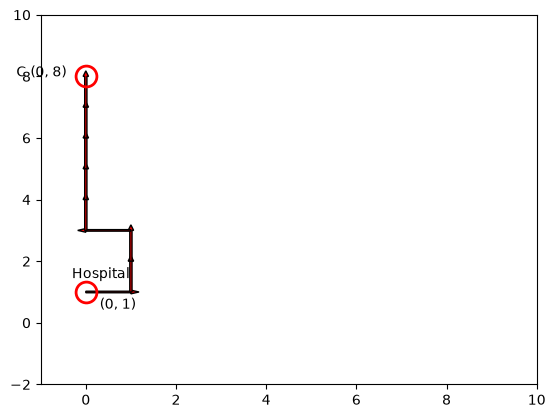

In [5]:
"""Test from Hospital to C"""

path = s.dijkstra(s.places["Hospital"], s.places["C"])
print(f"Shortest Path Length from Hospital to C is: {len(path)}")

plt.xlim(-1, 10)
plt.ylim(-2, 10)

plt.annotate("Hospital",
    xy=s.places['Hospital'],
    textcoords="offset points",
    xytext=(-10, 10),
    ha='left'
)
plt.annotate(str(s.places['Hospital']),
    xy=s.places['Hospital'],
    textcoords="offset points",
    xytext=(10, -12),
    ha='left'
)
plt.annotate(f"C {s.places['C']}",
    xy=s.places['C'],
    textcoords="offset points",
    xytext=(-50, 0),
    ha='left'
)
plt.plot(s.places['Hospital'][0], s.places['Hospital'][1], marker="o", markersize=15, markeredgecolor='red', markerfacecolor='none', markeredgewidth=2)
plt.plot(s.places['C'][0], s.places['C'][1], marker="o", markersize=15, markeredgecolor='red', markerfacecolor='none', markeredgewidth=2)

for i in range(1, len(path)):
    plt.arrow(path[i-1][0], path[i-1][1], path[i][0] - path[i-1][0], path[i][1] - path[i-1][1], facecolor="red", width = 0.05, head_width = 0.12)

plt.show()

Shortest Path Length from Hospital to D is: 13


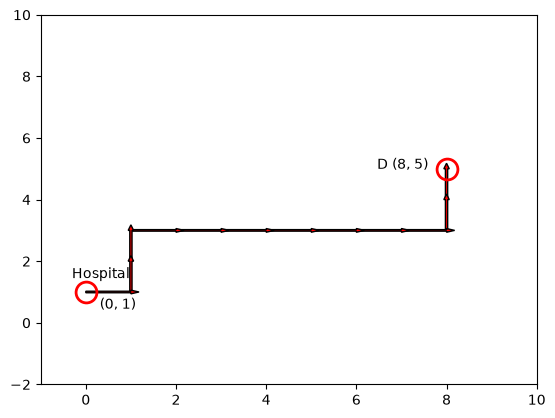

In [6]:
"""Test from Hospital to D"""

path = s.dijkstra(s.places["Hospital"], s.places["D"])
print(f"Shortest Path Length from Hospital to D is: {len(path)}")

plt.xlim(-1, 10)
plt.ylim(-2, 10)

plt.annotate("Hospital",
    xy=s.places['Hospital'],
    textcoords="offset points",
    xytext=(-10, 10),
    ha='left'
)
plt.annotate(str(s.places['Hospital']),
    xy=s.places['Hospital'],
    textcoords="offset points",
    xytext=(10, -12),
    ha='left'
)
plt.annotate(f"D {s.places['D']}",
    xy=s.places['D'],
    textcoords="offset points",
    xytext=(-50, 0),
    ha='left'
)
plt.plot(s.places['Hospital'][0], s.places['Hospital'][1], marker="o", markersize=15, markeredgecolor='red', markerfacecolor='none', markeredgewidth=2)
plt.plot(s.places['D'][0], s.places['D'][1], marker="o", markersize=15, markeredgecolor='red', markerfacecolor='none', markeredgewidth=2)

for i in reversed(range(1, len(path))):
    plt.arrow(path[i-1][0], path[i-1][1], path[i][0] - path[i-1][0], path[i][1] - path[i-1][1], facecolor="red", width = 0.05, head_width = 0.12)

plt.show()

Shortest Path Length from Hospital to E is: 9


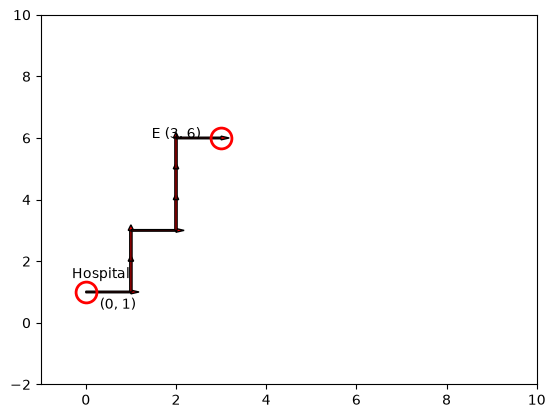

In [7]:
"""Test from Hospital to E"""

path = s.dijkstra(s.places["Hospital"], s.places["E"])
print(f"Shortest Path Length from Hospital to E is: {len(path)}")

plt.xlim(-1, 10)
plt.ylim(-2, 10)

plt.annotate("Hospital",
    xy=s.places['Hospital'],
    textcoords="offset points",
    xytext=(-10, 10),
    ha='left'
)
plt.annotate(str(s.places['Hospital']),
    xy=s.places['Hospital'],
    textcoords="offset points",
    xytext=(10, -12),
    ha='left'
)
plt.annotate(f"E {s.places['E']}",
    xy=s.places['E'],
    textcoords="offset points",
    xytext=(-50, 0),
    ha='left'
)
plt.plot(s.places['Hospital'][0], s.places['Hospital'][1], marker="o", markersize=15, markeredgecolor='red', markerfacecolor='none', markeredgewidth=2)
plt.plot(s.places['E'][0], s.places['E'][1], marker="o", markersize=15, markeredgecolor='red', markerfacecolor='none', markeredgewidth=2)

for i in range(1, len(path)):
    plt.arrow(path[i-1][0], path[i-1][1], path[i][0] - path[i-1][0], path[i][1] - path[i-1][1], facecolor="red", width = 0.05, head_width = 0.12)

plt.show()